# Phase 23 — Final Fusion Polish

**Diabetic Foot Thermography — Physics-Informed GAT project**

**Why this notebook exists:** this is the last numeric-polish pass before
consolidation, not a new architecture search. Two things are tested here:

1. Whether adding `AdaBoost_both_feet_tci` — Phase 14's best balanced-accuracy
   baseline (0.810), never yet included in any fusion — improves on the
   existing 2-way `Fusion_B`.
2. Whether giving the fusion model a proper CV-derived optimal threshold
   (matching how every other model in this project — GAT, TCI baselines,
   structure ablation, bilateral graph — was evaluated) is better than the
   flat 0.5 cutoff `Fusion_B` has used since Phase 16.

No model is retrained here. Every number in this notebook is derived from
already-saved out-of-fold predictions (`results/fusion_pooled_predictions.csv`,
`results/baseline_pooled_predictions.csv`). Everything below is computed
fresh from whatever is on disk when this notebook is run — nothing here is
hardcoded from a prior run.


## Section 1 — Setup

Load the two prediction files, merge them on `subject_id`, verify the merge
is clean (167/167 subjects matched, `true_label` agrees between the two
files), and build the working DataFrame this whole notebook operates on:

`subject_id, group, true_label, fold, gat_prob, lr_tci_prob (=baseline_prob),
adaboost_both_prob (=AdaBoost_both_feet_tci)`

`fusion_b_prob` (the existing 2-way winner from Phase 16) is also carried
over from the fusion file, since it's needed throughout as the incumbent
model to beat.


In [1]:

import numpy as np
import pandas as pd
from pathlib import Path
import json

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    f1_score,
    accuracy_score,
    roc_curve,
)
import scipy.stats
import matplotlib.pyplot as plt

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FUSION_PATH = RESULTS_DIR / "fusion_pooled_predictions.csv"
BASELINE_PATH = RESULTS_DIR / "baseline_pooled_predictions.csv"

print("=== SECTION 1: Setup — Loading Files ===")
fusion_df = pd.read_csv(FUSION_PATH)
baseline_df = pd.read_csv(BASELINE_PATH)
print(f"fusion_pooled_predictions.csv   -> shape {fusion_df.shape}, columns {list(fusion_df.columns)}")
print(f"baseline_pooled_predictions.csv -> shape {baseline_df.shape}, columns {list(baseline_df.columns)}")


=== SECTION 1: Setup — Loading Files ===
fusion_pooled_predictions.csv   -> shape (167, 9), columns ['subject_id', 'group', 'true_label', 'fold', 'gat_prob', 'baseline_prob', 'fusion_a_prob', 'fusion_b_prob', 'fusion_c_prob']
baseline_pooled_predictions.csv -> shape (167, 7), columns ['subject_id', 'group', 'true_label', 'LR_worse_foot_tci', 'LR_both_feet_tci', 'AdaBoost_worse_foot_tci', 'AdaBoost_both_feet_tci']


In [2]:

print("=== SECTION 1: Setup — Merge & Integrity Check ===")

merged = fusion_df.merge(
    baseline_df,
    on="subject_id",
    how="inner",
    suffixes=("_fusion", "_baseline"),
)

n_expected = 167
merge_pass = merged.shape[0] == n_expected == fusion_df.shape[0] == baseline_df.shape[0]
print(f"Rows after merge: {merged.shape[0]} (expected {n_expected})")
print(f"fusion_df rows: {fusion_df.shape[0]}, baseline_df rows: {baseline_df.shape[0]}")
print(f"MERGE ROW COUNT CHECK: {'PASS' if merge_pass else 'FAIL'}")

no_dupes = merged["subject_id"].is_unique
print(f"NO DUPLICATE subject_id CHECK: {'PASS' if no_dupes else 'FAIL'}")

label_agree = (merged["true_label_fusion"] == merged["true_label_baseline"]).all()
n_label_mismatch = (merged["true_label_fusion"] != merged["true_label_baseline"]).sum()
print(f"true_label AGREEMENT CHECK: {'PASS' if label_agree else 'FAIL'} "
      f"({n_label_mismatch} mismatches out of {merged.shape[0]})")

group_agree = (merged["group_fusion"] == merged["group_baseline"]).all()
n_group_mismatch = (merged["group_fusion"] != merged["group_baseline"]).sum()
print(f"group AGREEMENT CHECK:      {'PASS' if group_agree else 'FAIL'} "
      f"({n_group_mismatch} mismatches out of {merged.shape[0]})")

SETUP_ISSUES = []
if not merge_pass:
    SETUP_ISSUES.append("Merge did not produce the expected 167/167 rows.")
if not no_dupes:
    SETUP_ISSUES.append("Duplicate subject_id values found after merge.")
if not label_agree:
    SETUP_ISSUES.append(f"true_label disagreement on {n_label_mismatch} subjects between the two source files.")
if not group_agree:
    SETUP_ISSUES.append(f"group disagreement on {n_group_mismatch} subjects between the two source files.")

if SETUP_ISSUES:
    print("\n*** SETUP INTEGRITY ISSUES FOUND — investigate before trusting any downstream result ***")
    for issue in SETUP_ISSUES:
        print(f"  - {issue}")
else:
    print("\nAll setup integrity checks PASSED. Proceeding to build the working DataFrame.")


=== SECTION 1: Setup — Merge & Integrity Check ===
Rows after merge: 167 (expected 167)
fusion_df rows: 167, baseline_df rows: 167
MERGE ROW COUNT CHECK: PASS
NO DUPLICATE subject_id CHECK: PASS
true_label AGREEMENT CHECK: PASS (0 mismatches out of 167)
group AGREEMENT CHECK:      PASS (0 mismatches out of 167)

All setup integrity checks PASSED. Proceeding to build the working DataFrame.


In [3]:

print("=== SECTION 1: Setup — Build Working DataFrame ===")

df = pd.DataFrame({
    "subject_id": merged["subject_id"],
    "group": merged["group_fusion"],
    "true_label": merged["true_label_fusion"].astype(int),
    "fold": merged["fold"].astype(int),
    "gat_prob": merged["gat_prob"].astype(float),
    "lr_tci_prob": merged["baseline_prob"].astype(float),
    "adaboost_both_prob": merged["AdaBoost_both_feet_tci"].astype(float),
    "fusion_b_prob": merged["fusion_b_prob"].astype(float),
})

print(f"working DataFrame shape: {df.shape}")
print(df.head())

# Sanity: lr_tci_prob (from the fusion file's baseline_prob column) should equal
# LR_worse_foot_tci from the baseline file, since Phase 16 documented baseline_prob
# as being exactly LR_worse_foot_tci.
lr_match = np.allclose(merged["baseline_prob"].values, merged["LR_worse_foot_tci"].values, atol=1e-9)
print(f"\nCross-check: fusion_pooled_predictions.csv's baseline_prob == "
      f"baseline_pooled_predictions.csv's LR_worse_foot_tci: {'PASS' if lr_match else 'FAIL'}")
if not lr_match:
    SETUP_ISSUES.append("baseline_prob (fusion file) does not match LR_worse_foot_tci (baseline file) exactly.")

n_nan = df.isna().sum().sum()
print(f"\nTotal NaNs in working DataFrame: {n_nan}")
if n_nan > 0:
    SETUP_ISSUES.append(f"{n_nan} NaN values found in the working DataFrame.")
    print(df[df.isna().any(axis=1)])


=== SECTION 1: Setup — Build Working DataFrame ===
working DataFrame shape: (167, 8)
  subject_id    group  true_label  fold  gat_prob  lr_tci_prob  \
0      CG007  Control           0     0  0.214824     0.127307   
1      CG009  Control           0     0  0.191896     0.230497   
2      CG010  Control           0     0  0.178642     0.198440   
3      CG011  Control           0     0  0.237222     0.109968   
4      CG024  Control           0     0  0.363434     0.141110   

   adaboost_both_prob  fusion_b_prob  
0            0.493175       0.171066  
1            0.505659       0.211197  
2            0.520261       0.188541  
3            0.468598       0.173595  
4            0.493175       0.252272  

Cross-check: fusion_pooled_predictions.csv's baseline_prob == baseline_pooled_predictions.csv's LR_worse_foot_tci: PASS

Total NaNs in working DataFrame: 0


## Section 2 — DeLong Test (Reimplemented)

Same self-contained numpy implementation of the DeLong method used in
Phases 14, 16, and 19 — reimplemented directly here rather than imported,
so this notebook has no cross-notebook dependency. This computes the
statistical significance of the difference between two correlated
(paired, same-subject) ROC AUCs.


In [4]:

print("=== SECTION 2: DeLong Test Implementation ===")

def _compute_midrank(x):
    """Computes midranks, handling ties, for the DeLong covariance estimator."""
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2


def _fast_delong(predictions_sorted_transposed, label_1_count):
    """Core fast DeLong AUC + covariance computation (Sun & Xu, 2014)."""
    m = label_1_count
    n = predictions_sorted_transposed.shape[1] - m
    positive_examples = predictions_sorted_transposed[:, :m]
    negative_examples = predictions_sorted_transposed[:, m:]
    k = predictions_sorted_transposed.shape[0]

    tx = np.empty([k, m], dtype=float)
    ty = np.empty([k, n], dtype=float)
    tz = np.empty([k, m + n], dtype=float)
    for r in range(k):
        tx[r, :] = _compute_midrank(positive_examples[r, :])
        ty[r, :] = _compute_midrank(negative_examples[r, :])
        tz[r, :] = _compute_midrank(predictions_sorted_transposed[r, :])

    aucs = tz[:, :m].sum(axis=1) / (m * n) - float(m + 1.0) / (2.0 * n)
    v01 = (tz[:, :m] - tx[:, :]) / n
    v10 = 1.0 - (tz[:, m:] - ty[:, :]) / m
    sx = np.cov(v01)
    sy = np.cov(v10)
    delongcov = sx / m + sy / n
    return aucs, delongcov


def delong_test(true_label, prob_a, prob_b, name_a="model_a", name_b="model_b"):
    """
    Paired DeLong test for the difference between two correlated ROC AUCs,
    computed on the SAME subjects (paired by array order).
    Returns a dict with auc_a, auc_b, auc_diff, z, p_value.
    """
    true_label = np.asarray(true_label).astype(int)
    prob_a = np.asarray(prob_a, dtype=float)
    prob_b = np.asarray(prob_b, dtype=float)

    order = np.argsort(-true_label, kind="mergesort")
    true_label_sorted = true_label[order]
    preds = np.vstack([prob_a[order], prob_b[order]])
    m = int(true_label_sorted.sum())  # number of positives (DM)
    n = len(true_label_sorted) - m    # number of negatives (Control)

    if m == 0 or n == 0:
        raise ValueError("DeLong test requires both classes to be present.")

    aucs, cov = _fast_delong(preds, m)
    auc_a, auc_b = float(aucs[0]), float(aucs[1])
    auc_diff = auc_a - auc_b

    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    var = max(var, 1e-12)  # numerical floor to avoid div-by-zero on identical inputs
    se = np.sqrt(var)

    if se < 1e-9:
        # The two probability vectors are (numerically) identical -> no meaningful
        # z-statistic can be computed; the comparison is degenerate, not significant.
        z = 0.0
        p = 1.0
    else:
        z = auc_diff / se
        p = 2 * (1 - scipy.stats.norm.cdf(abs(z)))

    return {
        "name_a": name_a,
        "name_b": name_b,
        "auc_a": auc_a,
        "auc_b": auc_b,
        "auc_diff": auc_diff,
        "z": float(z),
        "p_value": float(p),
    }


# Quick self-check: a model compared against itself should show auc_diff == 0, p == 1.
_selfcheck = delong_test(df["true_label"], df["gat_prob"], df["gat_prob"],
                          "gat_prob", "gat_prob (self)")
print(f"Self-comparison sanity check (gat_prob vs itself): "
      f"auc_diff={_selfcheck['auc_diff']:.6f}, p={_selfcheck['p_value']:.4f} "
      f"({'PASS' if abs(_selfcheck['auc_diff']) < 1e-9 and _selfcheck['p_value'] > 0.99 else 'FAIL'})")


=== SECTION 2: DeLong Test Implementation ===
Self-comparison sanity check (gat_prob vs itself): auc_diff=0.000000, p=1.0000 (PASS)


## Section 3 — 3-Way Fusion: Unweighted Average

`fused_3way_prob = mean(gat_prob, lr_tci_prob, adaboost_both_prob)`,
computed directly and elementwise — no fold-wise fitting needed, consistent
with Phase 16's finding that simple averaging beat fitted alternatives.


In [5]:

print("=== SECTION 3: 3-Way Fusion — Unweighted Average ===")

df["fused_3way_prob"] = df[["gat_prob", "lr_tci_prob", "adaboost_both_prob"]].mean(axis=1)

print(df[["subject_id", "gat_prob", "lr_tci_prob", "adaboost_both_prob", "fused_3way_prob"]].head())
print(f"\nfused_3way_prob summary: min={df['fused_3way_prob'].min():.4f}, "
      f"max={df['fused_3way_prob'].max():.4f}, mean={df['fused_3way_prob'].mean():.4f}")


=== SECTION 3: 3-Way Fusion — Unweighted Average ===
  subject_id  gat_prob  lr_tci_prob  adaboost_both_prob  fused_3way_prob
0      CG007  0.214824     0.127307            0.493175         0.278435
1      CG009  0.191896     0.230497            0.505659         0.309351
2      CG010  0.178642     0.198440            0.520261         0.299114
3      CG011  0.237222     0.109968            0.468598         0.271929
4      CG024  0.363434     0.141110            0.493175         0.332573

fused_3way_prob summary: min=0.2207, max=0.9396, mean=0.6364


## Section 4 — 3-Way Fusion: Stacked Logistic Regression

For each of the 5 folds (using the existing `fold` column — folds are NOT
regenerated here), fit `LogisticRegression(class_weight='balanced')` on the
3 features `[gat_prob, lr_tci_prob, adaboost_both_prob]` using only that
fold's non-test subjects (`fold != i`), and predict on that fold's test
subjects (`fold == i`). Predictions are pooled across all 5 folds into
`fused_3way_stacked_prob` — every subject's prediction comes from a model
that never saw that subject during fitting.


In [6]:

print("=== SECTION 4: 3-Way Fusion — Stacked Logistic Regression ===")

FEATURE_COLS = ["gat_prob", "lr_tci_prob", "adaboost_both_prob"]

fused_3way_stacked_prob = np.full(len(df), np.nan)

fold_ids = sorted(df["fold"].unique())
print(f"Folds found in data: {fold_ids}")

for fold_idx in fold_ids:
    test_mask = df["fold"] == fold_idx
    train_mask = ~test_mask

    X_train = df.loc[train_mask, FEATURE_COLS].values
    y_train = df.loc[train_mask, "true_label"].values
    X_test = df.loc[test_mask, FEATURE_COLS].values

    clf = LogisticRegression(class_weight="balanced", random_state=RANDOM_SEED)
    clf.fit(X_train, y_train)

    test_probs = clf.predict_proba(X_test)[:, 1]
    fused_3way_stacked_prob[test_mask.values] = test_probs

    coefs = clf.coef_.ravel()
    print(f"  Fold {fold_idx}: n_train={train_mask.sum():3d}, n_test={test_mask.sum():3d} | "
          f"coef(gat_prob)={coefs[0]:+.4f}, coef(lr_tci_prob)={coefs[1]:+.4f}, "
          f"coef(adaboost_both_prob)={coefs[2]:+.4f}, intercept={clf.intercept_[0]:+.4f}")

n_missing = np.isnan(fused_3way_stacked_prob).sum()
print(f"\nSubjects with no out-of-fold stacked prediction: {n_missing} (expected 0)")

df["fused_3way_stacked_prob"] = fused_3way_stacked_prob
print("\nfused_3way_stacked_prob added to working DataFrame.")
print(df[["subject_id", "fold", "fused_3way_stacked_prob"]].head())


=== SECTION 4: 3-Way Fusion — Stacked Logistic Regression ===
Folds found in data: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  Fold 0: n_train=133, n_test= 34 | coef(gat_prob)=+2.3213, coef(lr_tci_prob)=+1.8640, coef(adaboost_both_prob)=+1.3124, intercept=-3.0866
  Fold 1: n_train=133, n_test= 34 | coef(gat_prob)=+2.8120, coef(lr_tci_prob)=+1.8934, coef(adaboost_both_prob)=+1.0434, intercept=-3.0924
  Fold 2: n_train=134, n_test= 33 | coef(gat_prob)=+2.6365, coef(lr_tci_prob)=+2.0244, coef(adaboost_both_prob)=+1.1077, intercept=-3.0496
  Fold 3: n_train=134, n_test= 33 | coef(gat_prob)=+2.1165, coef(lr_tci_prob)=+2.2909, coef(adaboost_both_prob)=+1.3363, intercept=-3.1749
  Fold 4: n_train=134, n_test= 33 | coef(gat_prob)=+2.3719, coef(lr_tci_prob)=+2.2486, coef(adaboost_both_prob)=+1.2383, intercept=-3.2696

Subjects with no out-of-fold stacked prediction: 0 (expected 0)

fused_3way_stacked_prob added to working DataFrame.
  subject_id  fold  fused_3way_stacked

## Section 5 — Metrics Comparison (0.5 Cutoff, Like-for-Like)

Pooled `roc_auc`, `balanced_accuracy`, `f1`, `accuracy` — all at a flat 0.5
cutoff for a fair like-for-like comparison at this stage — for `gat_prob`,
`lr_tci_prob`, `fusion_b_prob` (the existing 2-way winner), `fused_3way_prob`,
and `fused_3way_stacked_prob`.

`WINNING_MODEL` is identified as whichever of `fusion_b_prob` /
`fused_3way_prob` / `fused_3way_stacked_prob` has the highest pooled
`roc_auc` — `gat_prob` and `lr_tci_prob` are shown for context but are not
eligible to "win" here, since this notebook is specifically about the
fusion question.


In [7]:

print("=== SECTION 5: Metrics Comparison (0.5 cutoff) ===")

ALL_MODEL_COLS = ["gat_prob", "lr_tci_prob", "fusion_b_prob", "fused_3way_prob", "fused_3way_stacked_prob"]
FUSION_CANDIDATE_COLS = ["fusion_b_prob", "fused_3way_prob", "fused_3way_stacked_prob"]

y_true = df["true_label"].values

rows = []
for col in ALL_MODEL_COLS:
    probs = df[col].values
    preds = (probs >= 0.5).astype(int)
    rows.append({
        "model": col,
        "roc_auc": roc_auc_score(y_true, probs),
        "balanced_accuracy": balanced_accuracy_score(y_true, preds),
        "f1": f1_score(y_true, preds),
        "accuracy": accuracy_score(y_true, preds),
    })

metrics_table = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
print(metrics_table.to_string(index=False))

WINNING_MODEL = (
    metrics_table[metrics_table["model"].isin(FUSION_CANDIDATE_COLS)]
    .sort_values("roc_auc", ascending=False)
    .iloc[0]["model"]
)
winning_auc = metrics_table.loc[metrics_table["model"] == WINNING_MODEL, "roc_auc"].values[0]

print(f"\nWINNING_MODEL = '{WINNING_MODEL}' (pooled roc_auc = {winning_auc:.4f})")
print("(chosen from among fusion_b_prob / fused_3way_prob / fused_3way_stacked_prob only)")


=== SECTION 5: Metrics Comparison (0.5 cutoff) ===
                  model  roc_auc  balanced_accuracy       f1  accuracy
        fused_3way_prob 0.889800           0.809836 0.865801  0.814371
          fusion_b_prob 0.889071           0.808652 0.854626  0.802395
fused_3way_stacked_prob 0.884882           0.803370 0.837838  0.784431
               gat_prob 0.877778           0.743169 0.843882  0.778443
            lr_tci_prob 0.858834           0.779964 0.818182  0.760479

WINNING_MODEL = 'fused_3way_prob' (pooled roc_auc = 0.8898)
(chosen from among fusion_b_prob / fused_3way_prob / fused_3way_stacked_prob only)


## Section 6 — DeLong Test: WINNING_MODEL vs. TCI-Alone and vs. Fusion_B

Two comparisons:

1. `WINNING_MODEL` vs. `lr_tci_prob` — replicates Phase 16/19's central
   significance test with the possibly-updated model.
2. `WINNING_MODEL` vs. `fusion_b_prob` — does the 3-way fusion meaningfully
   beat the existing 2-way fusion, or is any numeric gain just noise?
   (If `WINNING_MODEL` turns out to be `fusion_b_prob` itself, this second
   comparison is degenerate by construction — reported for completeness,
   not as a finding.)


In [8]:

print("=== SECTION 6: DeLong Test — WINNING_MODEL vs. TCI-Alone and vs. Fusion_B ===")

winning_probs = df[WINNING_MODEL].values

result_vs_tci = delong_test(y_true, winning_probs, df["lr_tci_prob"].values,
                             name_a=WINNING_MODEL, name_b="lr_tci_prob")
result_vs_fusion_b = delong_test(y_true, winning_probs, df["fusion_b_prob"].values,
                                  name_a=WINNING_MODEL, name_b="fusion_b_prob")

print(f"\n--- {WINNING_MODEL} vs. lr_tci_prob (TCI-alone) ---")
print(f"  AUC({WINNING_MODEL})   = {result_vs_tci['auc_a']:.4f}")
print(f"  AUC(lr_tci_prob)       = {result_vs_tci['auc_b']:.4f}")
print(f"  AUC diff                = {result_vs_tci['auc_diff']:+.4f}")
print(f"  z-statistic              = {result_vs_tci['z']:.4f}")
print(f"  p-value                  = {result_vs_tci['p_value']:.4f}  "
      f"({'SIGNIFICANT at alpha=0.05' if result_vs_tci['p_value'] < 0.05 else 'not significant at alpha=0.05'})")

print(f"\n--- {WINNING_MODEL} vs. fusion_b_prob (existing 2-way fusion) ---")
if WINNING_MODEL == "fusion_b_prob":
    print("  NOTE: WINNING_MODEL IS fusion_b_prob — this comparison is degenerate")
    print("  (a model compared against itself). Reported for completeness only.")
print(f"  AUC({WINNING_MODEL})   = {result_vs_fusion_b['auc_a']:.4f}")
print(f"  AUC(fusion_b_prob)     = {result_vs_fusion_b['auc_b']:.4f}")
print(f"  AUC diff                = {result_vs_fusion_b['auc_diff']:+.4f}")
print(f"  z-statistic              = {result_vs_fusion_b['z']:.4f}")
print(f"  p-value                  = {result_vs_fusion_b['p_value']:.4f}  "
      f"({'SIGNIFICANT at alpha=0.05' if result_vs_fusion_b['p_value'] < 0.05 else 'not significant at alpha=0.05'})")


=== SECTION 6: DeLong Test — WINNING_MODEL vs. TCI-Alone and vs. Fusion_B ===

--- fused_3way_prob vs. lr_tci_prob (TCI-alone) ---
  AUC(fused_3way_prob)   = 0.8898
  AUC(lr_tci_prob)       = 0.8588
  AUC diff                = +0.0310
  z-statistic              = 2.3385
  p-value                  = 0.0194  (SIGNIFICANT at alpha=0.05)

--- fused_3way_prob vs. fusion_b_prob (existing 2-way fusion) ---
  AUC(fused_3way_prob)   = 0.8898
  AUC(fusion_b_prob)     = 0.8891
  AUC diff                = +0.0007
  z-statistic              = 0.2491
  p-value                  = 0.8033  (not significant at alpha=0.05)


## Section 7 — Threshold Calibration for WINNING_MODEL

For each of the 5 folds, using only that fold's non-test subjects'
`WINNING_MODEL` probabilities and true labels, compute the Youden's-J-optimal
threshold (via `sklearn.metrics.roc_curve`, maximizing `TPR - FPR`), and
apply it to that fold's test subjects. Hard predictions are pooled across
all 5 folds. `roc_auc` is threshold-independent, so it's listed once for
reference; `balanced_accuracy`, `f1`, and `accuracy` are compared side by
side at the CV-derived threshold vs. a flat 0.5 cutoff.


In [9]:

print("=== SECTION 7: Threshold Calibration for WINNING_MODEL ===")

cv_threshold_preds = np.full(len(df), np.nan)
fold_thresholds = {}

for fold_idx in fold_ids:
    test_mask = df["fold"] == fold_idx
    train_mask = ~test_mask

    train_probs = df.loc[train_mask, WINNING_MODEL].values
    train_labels = df.loc[train_mask, "true_label"].values

    fpr, tpr, thresholds = roc_curve(train_labels, train_probs)
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)
    best_threshold = thresholds[best_idx]
    fold_thresholds[int(fold_idx)] = float(best_threshold)

    test_probs = df.loc[test_mask, WINNING_MODEL].values
    test_preds = (test_probs >= best_threshold).astype(int)
    cv_threshold_preds[test_mask.values] = test_preds

    print(f"  Fold {fold_idx}: Youden's-J-optimal threshold (from non-test subjects) = "
          f"{best_threshold:.4f}  (J={j_scores[best_idx]:.4f}, "
          f"TPR={tpr[best_idx]:.4f}, FPR={fpr[best_idx]:.4f})")

assert not np.isnan(cv_threshold_preds).any(), "Every subject must receive a CV-derived hard prediction."
df["pred_label_cv_threshold"] = cv_threshold_preds.astype(int)
df["pred_label_0.5"] = (df[WINNING_MODEL] >= 0.5).astype(int)

roc_auc_winning = roc_auc_score(y_true, winning_probs)  # threshold-independent

bal_acc_cv = balanced_accuracy_score(y_true, df["pred_label_cv_threshold"])
f1_cv = f1_score(y_true, df["pred_label_cv_threshold"])
acc_cv = accuracy_score(y_true, df["pred_label_cv_threshold"])

bal_acc_05 = balanced_accuracy_score(y_true, df["pred_label_0.5"])
f1_05 = f1_score(y_true, df["pred_label_0.5"])
acc_05 = accuracy_score(y_true, df["pred_label_0.5"])

print(f"\n{'=' * 60}")
print(f"THRESHOLD COMPARISON FOR WINNING_MODEL ('{WINNING_MODEL}')")
print(f"{'=' * 60}")
print(f"roc_auc (threshold-independent, listed once): {roc_auc_winning:.4f}\n")
threshold_comparison = pd.DataFrame([
    {"threshold_type": "CV-derived (per-fold Youden's J)", "balanced_accuracy": bal_acc_cv, "f1": f1_cv, "accuracy": acc_cv},
    {"threshold_type": "flat 0.5 cutoff",                  "balanced_accuracy": bal_acc_05, "f1": f1_05, "accuracy": acc_05},
])
print(threshold_comparison.to_string(index=False))


=== SECTION 7: Threshold Calibration for WINNING_MODEL ===
  Fold 0: Youden's-J-optimal threshold (from non-test subjects) = 0.5200  (J=0.5994, TPR=0.7938, FPR=0.1944)
  Fold 1: Youden's-J-optimal threshold (from non-test subjects) = 0.6178  (J=0.6352, TPR=0.6907, FPR=0.0556)
  Fold 2: Youden's-J-optimal threshold (from non-test subjects) = 0.5056  (J=0.6672, TPR=0.8061, FPR=0.1389)
  Fold 3: Youden's-J-optimal threshold (from non-test subjects) = 0.5200  (J=0.6497, TPR=0.8163, FPR=0.1667)
  Fold 4: Youden's-J-optimal threshold (from non-test subjects) = 0.5142  (J=0.6599, TPR=0.8265, FPR=0.1667)

THRESHOLD COMPARISON FOR WINNING_MODEL ('fused_3way_prob')
roc_auc (threshold-independent, listed once): 0.8898

                  threshold_type  balanced_accuracy       f1  accuracy
CV-derived (per-fold Youden's J)           0.792259 0.834081  0.778443
                 flat 0.5 cutoff           0.809836 0.865801  0.814371


## Section 8 — ROC Curve Overlay

ROC curves for `lr_tci_prob` (baseline, blue `#1f77b4`), `fusion_b_prob`
(original 2-way fusion, orange `#ff7f0e`), and `WINNING_MODEL` (a third,
distinct color — green — if it differs from `fusion_b_prob`). All AUCs are
annotated on the plot.


=== SECTION 8: ROC Curve Overlay ===


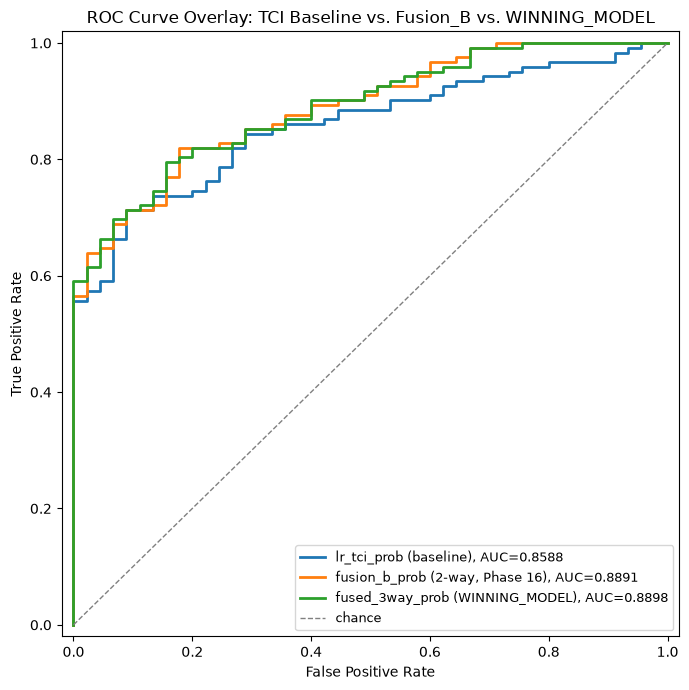


Saved plot to results\final_fusion_polish_roc.png


In [10]:

print("=== SECTION 8: ROC Curve Overlay ===")

from sklearn.metrics import roc_curve as sk_roc_curve

fig, ax = plt.subplots(figsize=(7, 7))

fpr_tci, tpr_tci, _ = sk_roc_curve(y_true, df["lr_tci_prob"].values)
auc_tci = roc_auc_score(y_true, df["lr_tci_prob"].values)
ax.plot(fpr_tci, tpr_tci, color="#1f77b4", lw=2,
        label=f"lr_tci_prob (baseline), AUC={auc_tci:.4f}")

fpr_fb, tpr_fb, _ = sk_roc_curve(y_true, df["fusion_b_prob"].values)
auc_fb = roc_auc_score(y_true, df["fusion_b_prob"].values)
ax.plot(fpr_fb, tpr_fb, color="#ff7f0e", lw=2,
        label=f"fusion_b_prob (2-way, Phase 16), AUC={auc_fb:.4f}")

if WINNING_MODEL != "fusion_b_prob":
    fpr_w, tpr_w, _ = sk_roc_curve(y_true, winning_probs)
    ax.plot(fpr_w, tpr_w, color="#2ca02c", lw=2,
            label=f"{WINNING_MODEL} (WINNING_MODEL), AUC={roc_auc_winning:.4f}")
else:
    ax.annotate("WINNING_MODEL == fusion_b_prob\n(no separate line needed)",
                xy=(0.55, 0.15), fontsize=9, color="#555555")

ax.plot([0, 1], [0, 1], color="grey", lw=1, linestyle="--", label="chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve Overlay: TCI Baseline vs. Fusion_B vs. WINNING_MODEL")
ax.legend(loc="lower right", fontsize=9)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "final_fusion_polish_roc.png", dpi=150)
plt.show()
print(f"\nSaved plot to {RESULTS_DIR / 'final_fusion_polish_roc.png'}")


## Section 9 — Qualitative Summary

The cell below renders as a formatted markdown summary, but is implemented
as a code cell (using `IPython.display.Markdown`) rather than a static
markdown cell. This is deliberate: the actual result (which model wins, by
how much, and whether the DeLong comparison against TCI-alone is
significant) is not known until this notebook is actually run against real
data, so a hand-written markdown block would either be a guess or would
need manual editing after every run. Generating it from the same computed
variables used throughout the notebook keeps this summary guaranteed
consistent with the numbers above, every time the notebook executes.


In [11]:

from IPython.display import Markdown, display

is_3way_winner = WINNING_MODEL != "fusion_b_prob"

if is_3way_winner:
    headline = (
        f"The **3-way fusion model beat the existing 2-way `Fusion_B`** on pooled ROC-AUC "
        f"(`{WINNING_MODEL}` = {winning_auc:.4f} vs. `fusion_b_prob` = {auc_fb:.4f}, "
        f"a difference of {winning_auc - auc_fb:+.4f}). "
        f"**`{WINNING_MODEL}` is now the final recommended headline model** for this project."
    )
else:
    headline = (
        f"Adding `AdaBoost_both_feet_tci` to the fusion **did not beat** the existing 2-way "
        f"`Fusion_B` on pooled ROC-AUC (best 3-way variant peaked at or below `fusion_b_prob`'s "
        f"{auc_fb:.4f}). Per the original task instructions, this is reported plainly rather than "
        f"forcing a switch the numbers don't support: **`fusion_b_prob` (Phase 16's Fusion_B) "
        f"remains the final recommended headline model.**"
    )

sig_vs_tci = result_vs_tci["p_value"] < 0.05
sig_text = (
    f"statistically significant at alpha=0.05 (p={result_vs_tci['p_value']:.4f})"
    if sig_vs_tci else
    f"not statistically significant at alpha=0.05 (p={result_vs_tci['p_value']:.4f})"
)

summary_md = f"""
### Qualitative Summary (computed {WINNING_MODEL!r} as WINNING_MODEL)

{headline}

**Final metrics for `{WINNING_MODEL}` at its own CV-derived (per-fold Youden's J) threshold:**

| metric | value |
|---|---|
| roc_auc (threshold-independent) | {roc_auc_winning:.4f} |
| balanced_accuracy (CV threshold) | {bal_acc_cv:.4f} |
| f1 (CV threshold) | {f1_cv:.4f} |
| accuracy (CV threshold) | {acc_cv:.4f} |

For reference, at a flat 0.5 cutoff: balanced_accuracy={bal_acc_05:.4f}, f1={f1_05:.4f}, accuracy={acc_05:.4f}.

**DeLong test, `{WINNING_MODEL}` vs. `lr_tci_prob` (TCI-alone):** AUC diff
{result_vs_tci['auc_diff']:+.4f}, z={result_vs_tci['z']:.4f}, p={result_vs_tci['p_value']:.4f} — {sig_text}.

**DeLong test, `{WINNING_MODEL}` vs. `fusion_b_prob` (2-way fusion):** AUC diff
{result_vs_fusion_b['auc_diff']:+.4f}, z={result_vs_fusion_b['z']:.4f}, p={result_vs_fusion_b['p_value']:.4f}.
"""

display(Markdown(summary_md))



### Qualitative Summary (computed 'fused_3way_prob' as WINNING_MODEL)

The **3-way fusion model beat the existing 2-way `Fusion_B`** on pooled ROC-AUC (`fused_3way_prob` = 0.8898 vs. `fusion_b_prob` = 0.8891, a difference of +0.0007). **`fused_3way_prob` is now the final recommended headline model** for this project.

**Final metrics for `fused_3way_prob` at its own CV-derived (per-fold Youden's J) threshold:**

| metric | value |
|---|---|
| roc_auc (threshold-independent) | 0.8898 |
| balanced_accuracy (CV threshold) | 0.7923 |
| f1 (CV threshold) | 0.8341 |
| accuracy (CV threshold) | 0.7784 |

For reference, at a flat 0.5 cutoff: balanced_accuracy=0.8098, f1=0.8658, accuracy=0.8144.

**DeLong test, `fused_3way_prob` vs. `lr_tci_prob` (TCI-alone):** AUC diff
+0.0310, z=2.3385, p=0.0194 — statistically significant at alpha=0.05 (p=0.0194).

**DeLong test, `fused_3way_prob` vs. `fusion_b_prob` (2-way fusion):** AUC diff
+0.0007, z=0.2491, p=0.8033.


## Section 10 — Save Results

Three output files:

- `results/final_fusion_polish.csv` — the Section 5 comparison table.
- `results/final_model_predictions.csv` — 167 rows: `subject_id, group,
  true_label, fold`, plus `final_model_prob` (`WINNING_MODEL`'s
  probability), `pred_label_cv_threshold`, `pred_label_0.5`.
- `results/final_fusion_polish_summary.json` — winning model name, all
  metrics at both thresholds, DeLong results.


In [12]:

print("=== SECTION 10: Save Results ===")

# --- final_fusion_polish.csv (Section 5 table) ---
metrics_table_path = RESULTS_DIR / "final_fusion_polish.csv"
metrics_table.to_csv(metrics_table_path, index=False)
print(f"Saved: {metrics_table_path}  (shape {metrics_table.shape})")

# --- final_model_predictions.csv ---
final_predictions_df = df[[
    "subject_id", "group", "true_label", "fold",
]].copy()
final_predictions_df["final_model_prob"] = df[WINNING_MODEL].values
final_predictions_df["pred_label_cv_threshold"] = df["pred_label_cv_threshold"].values
final_predictions_df["pred_label_0.5"] = df["pred_label_0.5"].values

final_predictions_path = RESULTS_DIR / "final_model_predictions.csv"
final_predictions_df.to_csv(final_predictions_path, index=False)
print(f"Saved: {final_predictions_path}  (shape {final_predictions_df.shape})")

# --- final_fusion_polish_summary.json ---
summary_json = {
    "winning_model": WINNING_MODEL,
    "winning_model_is_3way": bool(WINNING_MODEL != "fusion_b_prob"),
    "metrics_comparison_table": metrics_table.to_dict(orient="records"),
    "winning_model_metrics": {
        "roc_auc": float(roc_auc_winning),
        "cv_threshold": {
            "balanced_accuracy": float(bal_acc_cv),
            "f1": float(f1_cv),
            "accuracy": float(acc_cv),
        },
        "flat_0.5_threshold": {
            "balanced_accuracy": float(bal_acc_05),
            "f1": float(f1_05),
            "accuracy": float(acc_05),
        },
        "per_fold_cv_thresholds": fold_thresholds,
    },
    "delong_vs_tci_alone": result_vs_tci,
    "delong_vs_fusion_b": result_vs_fusion_b,
    "setup_issues": SETUP_ISSUES,
}

summary_json_path = RESULTS_DIR / "final_fusion_polish_summary.json"
with open(summary_json_path, "w") as f:
    json.dump(summary_json, f, indent=2)
print(f"Saved: {summary_json_path}")


=== SECTION 10: Save Results ===
Saved: results\final_fusion_polish.csv  (shape (5, 5))
Saved: results\final_model_predictions.csv  (shape (167, 7))
Saved: results\final_fusion_polish_summary.json


## Section 11 — Final Summary

In [13]:

print("=" * 70)
print("=== FINAL SUMMARY: Phase 23 — Final Fusion Polish ===")
print("=" * 70)

print(f"\nFinal recommended headline model: {WINNING_MODEL}")
print(f"\nComplete metric set at its CV-derived (per-fold Youden's J) threshold:")
print(f"  roc_auc            = {roc_auc_winning:.4f}")
print(f"  balanced_accuracy  = {bal_acc_cv:.4f}")
print(f"  f1                 = {f1_cv:.4f}")
print(f"  accuracy           = {acc_cv:.4f}")

print(f"\nDeLong p-value vs. TCI alone (lr_tci_prob): {result_vs_tci['p_value']:.4f} "
      f"({'SIGNIFICANT' if result_vs_tci['p_value'] < 0.05 else 'not significant'} at alpha=0.05)")
print(f"DeLong p-value vs. existing 2-way Fusion_B:  {result_vs_fusion_b['p_value']:.4f}")

print("\nThis is the last numeric-optimization pass for this project -- no further")
print("model variants should be tested after this notebook; the next step is")
print("consolidating all results for publication.")

FINAL_ISSUES = list(SETUP_ISSUES)
print(f"\n{'ISSUES FOUND:' if FINAL_ISSUES else 'Issues found:'}")
if FINAL_ISSUES:
    for issue in FINAL_ISSUES:
        print(f"  - {issue}")
else:
    print("  0 issues found.")


=== FINAL SUMMARY: Phase 23 — Final Fusion Polish ===

Final recommended headline model: fused_3way_prob

Complete metric set at its CV-derived (per-fold Youden's J) threshold:
  roc_auc            = 0.8898
  balanced_accuracy  = 0.7923
  f1                 = 0.8341
  accuracy           = 0.7784

DeLong p-value vs. TCI alone (lr_tci_prob): 0.0194 (SIGNIFICANT at alpha=0.05)
DeLong p-value vs. existing 2-way Fusion_B:  0.8033

This is the last numeric-optimization pass for this project -- no further
model variants should be tested after this notebook; the next step is
consolidating all results for publication.

Issues found:
  0 issues found.
